In [4]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.datasets import cifar10

from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

print("TensorFlow version:", tf.__version__)


TensorFlow version: 2.20.0


In [8]:
import os

print("Input folders:")
print(os.listdir("/kaggle/input"))

print("\nInside datasets:")
print(os.listdir("/kaggle/input/datasets"))

Input folders:
['notebooks', 'datasets']

Inside datasets:
['pankrzysiu']


In [9]:
import os

base_path = "/kaggle/input/datasets"

for folder in os.listdir(base_path):
    print("Folder:", folder)
    print("Files:", os.listdir(os.path.join(base_path, folder)))

Folder: pankrzysiu
Files: ['cifar10-python']


In [10]:
def load_cifar_file(file_path):
    with open(file_path, "rb") as file:
        data = pickle.load(file, encoding="bytes")
    
    images = data[b"data"]
    labels = data[b"labels"]
    
    return images, labels


# Find the folder containing data_batch_1
cifar_folder = None

for root, dirs, files in os.walk(base_path):
    if "data_batch_1" in files:
        cifar_folder = root
        break

print("CIFAR-10 folder:", cifar_folder)

CIFAR-10 folder: /kaggle/input/datasets/pankrzysiu/cifar10-python/cifar-10-batches-py


In [13]:
import pickle
x_train_list = []
y_train_list = []

for i in range(1, 6):
    file_path = os.path.join(cifar_folder, f"data_batch_{i}")
    
    images, labels = load_cifar_file(file_path)
    
    x_train_list.append(images)
    y_train_list.extend(labels)

x_train = np.concatenate(x_train_list)
y_train = np.array(y_train_list)

# Load test data
test_path = os.path.join(cifar_folder, "test_batch")

x_test, y_test = load_cifar_file(test_path)

# Convert test labels from list to NumPy array
y_test = np.array(y_test)

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

Training images: (50000, 3072)
Training labels: (50000,)
Testing images: (10000, 3072)
Testing labels: (10000,)


In [14]:
# Convert training images to 32x32x3
x_train = x_train.reshape(-1, 3, 32, 32)
x_train = x_train.transpose(0, 2, 3, 1)

# Convert testing images to 32x32x3
x_test = x_test.reshape(-1, 3, 32, 32)
x_test = x_test.transpose(0, 2, 3, 1)

print("Training image shape:", x_train.shape)
print("Testing image shape:", x_test.shape)

Training image shape: (50000, 32, 32, 3)
Testing image shape: (10000, 32, 32, 3)


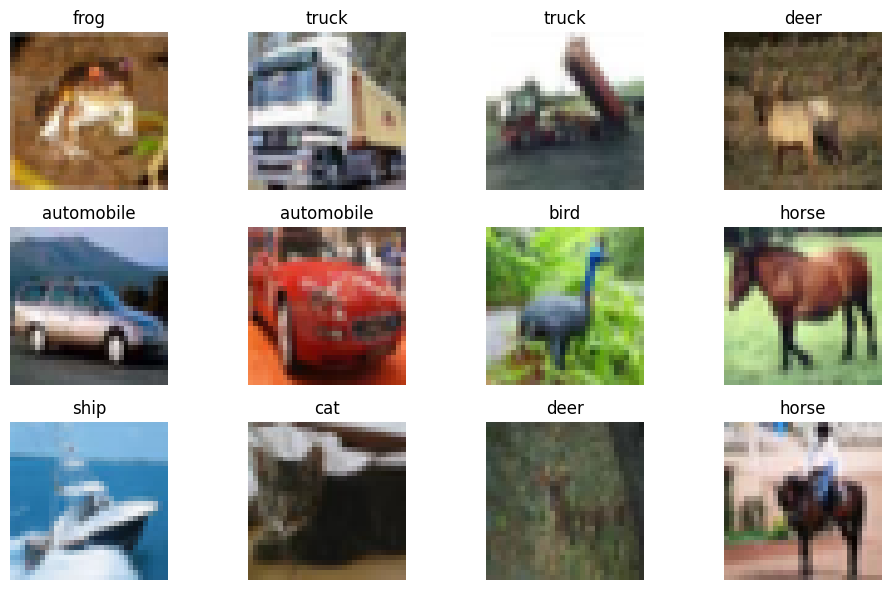

In [15]:
# CIFAR-10 class names
class_names = [
    "airplane",
    "automobile",
    "bird",
    "cat",
    "deer",
    "dog",
    "frog",
    "horse",
    "ship",
    "truck"
]

# Display 12 sample images
plt.figure(figsize=(10, 6))

for i in range(12):
    plt.subplot(3, 4, i + 1)
    
    plt.imshow(x_train[i])
    
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [16]:
# Normalize pixel values from 0-255 to 0-1

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

print("Minimum pixel value:", x_train.min())
print("Maximum pixel value:", x_train.max())

Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [17]:
from sklearn.model_selection import train_test_split

x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=5000,
    random_state=42,
    stratify=y_train
)

print("Training data:", x_train.shape)
print("Training labels:", y_train.shape)

print("Validation data:", x_val.shape)
print("Validation labels:", y_val.shape)

print("Testing data:", x_test.shape)
print("Testing labels:", y_test.shape)

Training data: (45000, 32, 32, 3)
Training labels: (45000,)
Validation data: (5000, 32, 32, 3)
Validation labels: (5000,)
Testing data: (10000, 32, 32, 3)
Testing labels: (10000,)


In [18]:
from tensorflow.keras import models, layers

model = models.Sequential([
    
    # Convolution Layer 1
    layers.Conv2D(
        32,
        (3, 3),
        activation="relu",
        input_shape=(32, 32, 3)
    ),
    
    # Max Pooling Layer 1
    layers.MaxPooling2D((2, 2)),
    
    # Convolution Layer 2
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    
    # Max Pooling Layer 2
    layers.MaxPooling2D((2, 2)),
    
    # Convolution Layer 3
    layers.Conv2D(
        64,
        (3, 3),
        activation="relu"
    ),
    
    # Flatten
    layers.Flatten(),
    
    # Fully Connected Layer
    layers.Dense(64, activation="relu"),
    
    # Output Layer - 10 CIFAR-10 classes
    layers.Dense(10, activation="softmax")
])

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2026-08-10 05:59:33.536437: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 4, 4, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        65,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 122,570 (478.79 KB)

 Trainable params: 122,570 (478.79 KB)

 Non-trainable params: 0 (0.00 B)

In [20]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully.")

Model compiled successfully.


In [21]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(x_val, y_val)
)

Epoch 1/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 31s 42ms/step - accuracy: 0.4013 - loss: 1.6411 - val_accuracy: 0.5142 - val_loss: 1.3392
Epoch 2/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.5466 - loss: 1.2659 - val_accuracy: 0.5434 - val_loss: 1.2900
Epoch 3/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 43ms/step - accuracy: 0.6084 - loss: 1.1053 - val_accuracy: 0.6286 - val_loss: 1.0608
Epoch 4/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 30s 43ms/step - accuracy: 0.6491 - loss: 0.9996 - val_accuracy: 0.6654 - val_loss: 0.9672
Epoch 5/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.6766 - loss: 0.9223 - val_accuracy: 0.6676 - val_loss: 0.9425
Epoch 6/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.6961 - loss: 0.8696 - val_accuracy: 0.6906 - val_loss: 0.9071
Epoch 7/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 28s 40ms/step - accuracy: 0.7131 - loss: 0.8199 - val_accuracy: 0.6944 - val_loss: 0.8835
Epoch 8/10
704/704 ━━━━━━━━━━━━━━━━━━━━ 29s 41ms/step - accuracy: 0.7306 - loss: 0.7680 - 

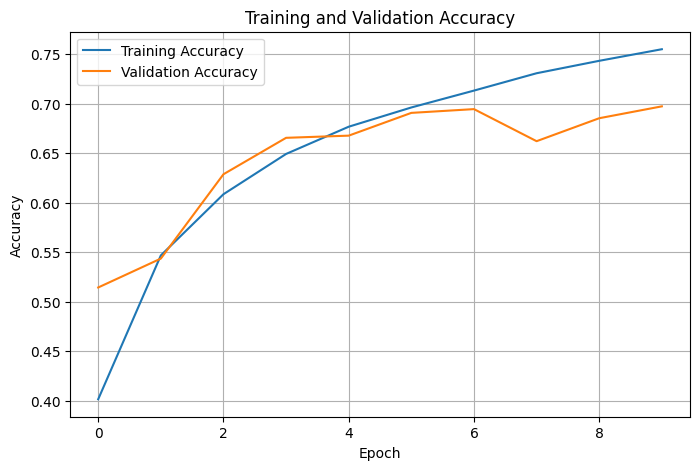

In [22]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")

plt.legend()
plt.grid()

plt.show()

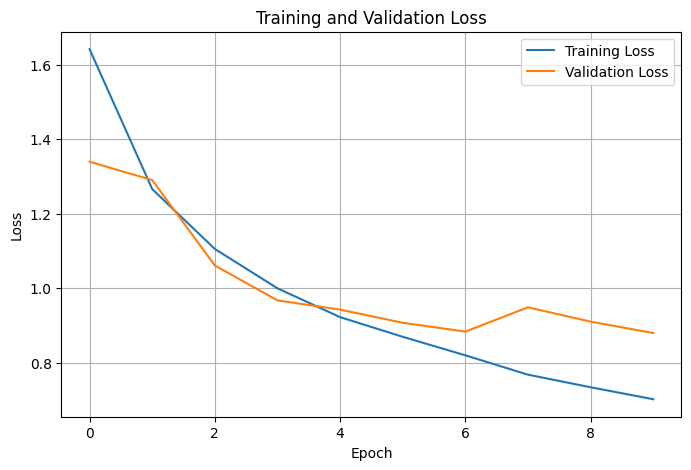

In [23]:
plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")

plt.legend()
plt.grid()

plt.show()

In [24]:
test_loss, test_accuracy = model.evaluate(
    x_test,
    y_test,
    verbose=2
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
print("Test Accuracy (%):", test_accuracy * 100)

313/313 - 3s - 8ms/step - accuracy: 0.6941 - loss: 0.9053
Test Loss: 0.9052770733833313
Test Accuracy: 0.694100022315979
Test Accuracy (%): 69.4100022315979


In [25]:
# Generate predictions for test images
predictions = model.predict(x_test)

# Convert probability predictions into class numbers
predicted_classes = np.argmax(predictions, axis=1)

print("Predictions generated successfully!")
print("Actual labels:   ", y_test[:20])
print("Predicted labels:", predicted_classes[:20])

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step
Predictions generated successfully!
Actual labels:    [3 8 8 0 6 6 1 6 3 1 0 9 5 7 9 8 5 7 8 6]
Predicted labels: [3 1 1 0 6 6 9 6 3 1 4 9 5 7 9 8 5 7 8 6]


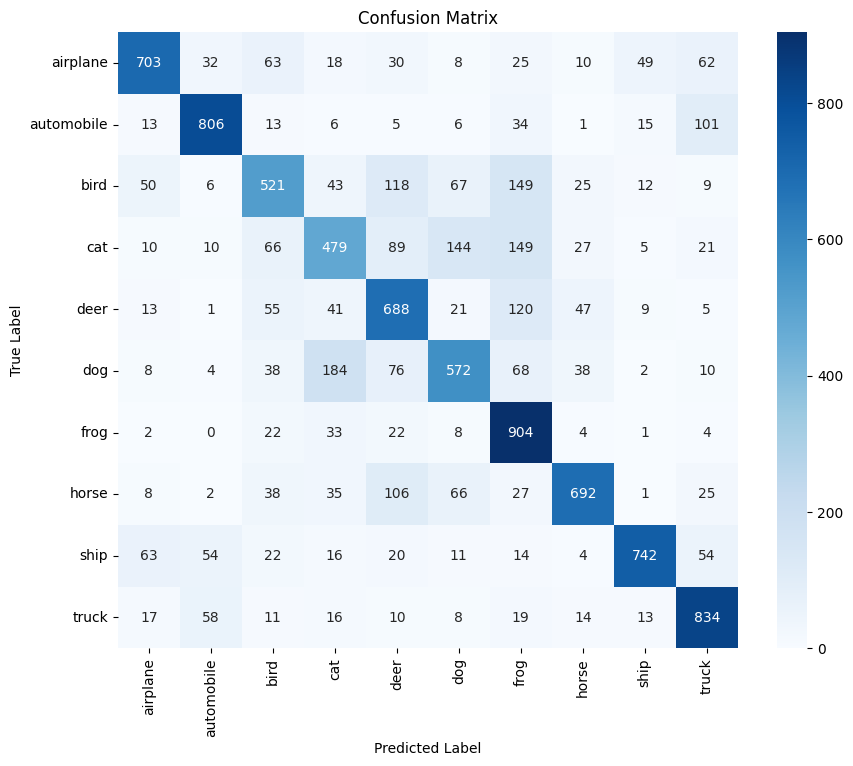

In [26]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Create confusion matrix
cm = confusion_matrix(
    y_test,
    predicted_classes
)

# Display confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

plt.show()

In [27]:
from sklearn.metrics import classification_report

report = classification_report(
    y_test,
    predicted_classes,
    target_names=class_names
)

print(report)

              precision    recall  f1-score   support

    airplane       0.79      0.70      0.75      1000
  automobile       0.83      0.81      0.82      1000
        bird       0.61      0.52      0.56      1000
         cat       0.55      0.48      0.51      1000
        deer       0.59      0.69      0.64      1000
         dog       0.63      0.57      0.60      1000
        frog       0.60      0.90      0.72      1000
       horse       0.80      0.69      0.74      1000
        ship       0.87      0.74      0.80      1000
       truck       0.74      0.83      0.78      1000

    accuracy                           0.69     10000
   macro avg       0.70      0.69      0.69     10000
weighted avg       0.70      0.69      0.69     10000



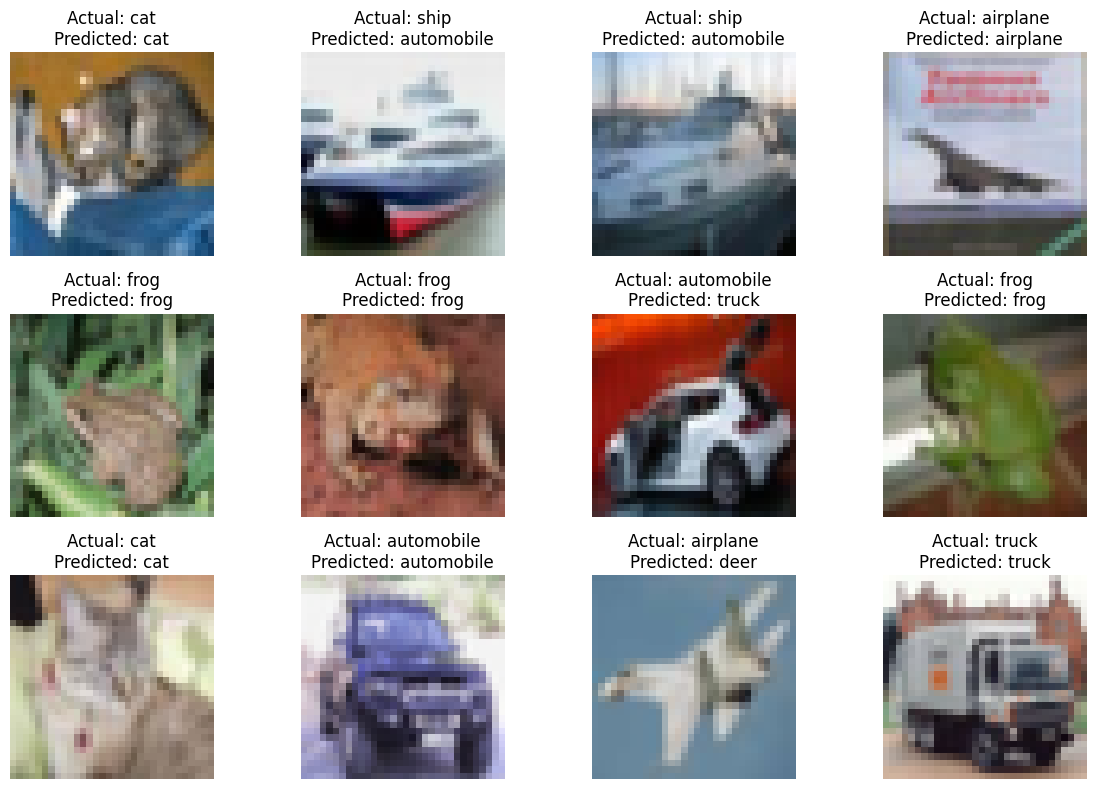

In [28]:
# Display sample predictions

plt.figure(figsize=(12, 8))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    plt.imshow(x_test[i])

    actual = class_names[y_test[i]]
    predicted = class_names[predicted_classes[i]]

    plt.title(
        "Actual: " + actual +
        "\nPredicted: " + predicted
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [29]:
# Find misclassified images

misclassified = np.where(
    predicted_classes != y_test
)[0]

print(
    "Number of misclassified images:",
    len(misclassified)
)

Number of misclassified images: 3059


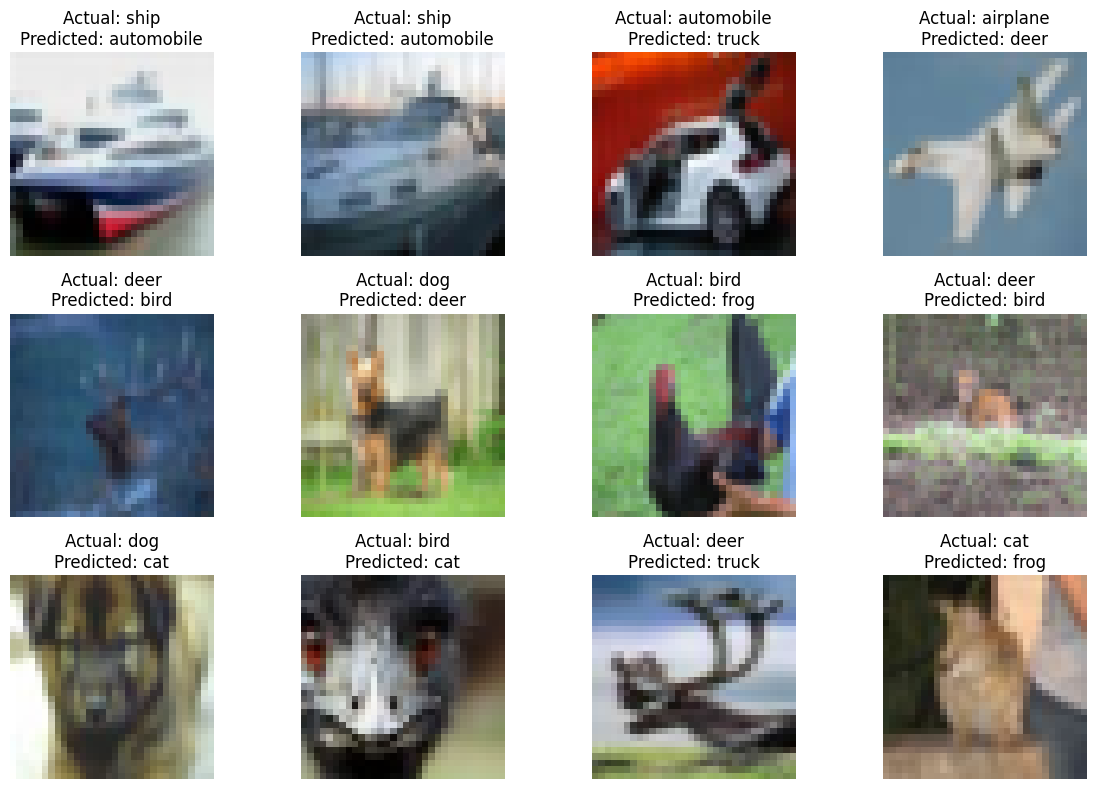

In [30]:
# Display the first 12 misclassified images

plt.figure(figsize=(12, 8))

for i, index in enumerate(misclassified[:12]):
    
    plt.subplot(3, 4, i + 1)
    
    plt.imshow(x_test[index])
    
    actual = class_names[y_test[index]]
    predicted = class_names[predicted_classes[index]]
    
    plt.title(
        "Actual: " + actual +
        "\nPredicted: " + predicted
    )
    
    plt.axis("off")

plt.tight_layout()
plt.show()